# Mapa de Bogotá · datos originales y datos con tratamiento

El selector ofrece exactamente dos opciones: **Datos originales** (sin relleno
temporal) y **Datos con tratamiento** (calendario 2015–2025 completo). Abre en
Datos con tratamiento y cada sector tiene una curva por variable. El mapa
conserva los **1.160 sectores catastrales**.

Los datos originales se conservan. El tratamiento completa huecos con estimación
y variación sintética reproducible identificadas; **no recupera mediciones
históricas ni alimenta el HGB de pronósticos**.

Las fuentes descargadas abarcan 100 fechas distintas: en 2015–2024 predomina un
solo día por año y 2025 aporta el primer trimestre. Completar el calendario no
demuestra que haya once años de mediciones continuas. Este notebook se ejecuta
con `requirements-research.txt` y no modifica las fuentes descargadas.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'research/neighborhood_history.py').exists())
sys.path.insert(0, str(ROOT))
from research.neighborhood_history import observations, daily_observations, station_locations, complete_calendar, features
from dash2 import neighborhood_data as maps
from dash2.map_scenarios import fill_short_gaps, SIMULATION_SEED
from dash2.rmcab_data import VARIABLES
raw = observations(ROOT)
daily = daily_observations(raw, station_locations(root=ROOT))
published, centroids, manifest = maps.load_history()
print(f'{raw.report_date.nunique()} fechas de fuente; {len(centroids)} sectores; semilla {SIMULATION_SEED}')


100 fechas de fuente; 1160 sectores; semilla 20251024


## Qué se conserva y cómo se rellenan los huecos

Se promedian las horas disponibles por estación y día del reporte. Se conservan
valores, horas y procedencia; los promedios con pocas horas siguen siendo parciales.

**Datos originales** mantiene los huecos. **Datos con tratamiento** aplica dos
etapas: interpolación lineal de tramos completos de hasta tres días, entre dos
observaciones de la misma estación y variable, y estimación KNN para el resto.
El límite de tres días corresponde a la primera etapa; no limita la cobertura
del modo con tratamiento. Sus rellenos largos incluyen la variación sintética
documentada más adelante. El proceso es retrospectivo y puede usar datos posteriores.

In [2]:
# Reproducir el paquete en memoria y comprobar que no cambia las fuentes.
rebuilt = complete_calendar(daily)
keys = ['station_id', 'report_date']
original = daily.set_index(keys)
actual = rebuilt.set_index(keys)
for var in VARIABLES:
    observed = original[var].dropna()
    np.testing.assert_allclose(actual.loc[observed.index, var], observed, atol=1e-7, rtol=0)
    np.testing.assert_allclose(rebuilt[f'{var}_short_gap'], published[f'{var}_short_gap'], equal_nan=True, atol=1e-7, rtol=0)
example = pd.Series([np.nan, 10, np.nan, np.nan, np.nan, 18, np.nan, np.nan, np.nan, np.nan, 30, np.nan])
display(pd.DataFrame({'original': example, 'huecos_cortos': fill_short_gaps(example)}))
assert fill_short_gaps(example).iloc[6:10].isna().all()
print('Mediciones preservadas; bordes y huecos largos sin rellenar.')


,original,huecos_cortos
0,NaN,NaN
1,10.0,10.0
2,NaN,12.0
3,NaN,14.0
4,NaN,16.0
5,18.0,18.0
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


Mediciones preservadas; bordes y huecos largos sin rellenar.


In [3]:
coverage = []
for year in range(2015, 2026):
    _, info = maps.aggregates(year, 'all', 'estimated')
    coverage.append({'año': year, 'calendario': info['calendar_days'],
                     **{f'{var}_fuentes': info[var]['source_days'] for var in VARIABLES},
                     'temperatura_huecos_cortos': info['temperature']['short_gap_days'],
                     'temperatura_días_representados': info['temperature']['represented_days'], 'temperatura_días_rellenados': info['temperature']['days_added']})
display(pd.DataFrame(coverage))
assert maps.aggregates(2015, 12, 'observed')[0].temperature_mean.isna().all()


,año,calendario,pm_25_fuentes,pm_10_fuentes,temperature_fuentes,humidity_fuentes,temperatura_huecos_cortos,temperatura_días_representados,temperatura_días_rellenados
0,2015,365,1,1,1,1,0,365,364
1,2016,366,1,1,1,1,0,366,365
2,2017,365,1,1,1,1,0,365,364
3,2018,365,1,1,1,1,0,365,364
4,2019,365,1,1,1,1,0,365,364
5,2020,366,1,1,1,1,0,366,365
6,2021,365,1,1,1,1,0,365,364
7,2022,365,1,1,1,1,0,365,364
8,2023,365,1,1,1,1,0,365,364
9,2024,366,1,1,1,1,0,366,365


## Estimación espacial y lectura de las curvas

IDW combina las cuatro estaciones disponibles más cercanas al centroide de cada
sector (haversine, potencia 2, piso 0,1 km). Las mediciones tienen prioridad sobre
los rellenos. Son estimaciones espaciales, no mediciones directas del barrio ni
promedios ponderados por toda el área del polígono. Las distancias a estaciones
y sus traslados históricos no verificados limitan la interpretación.

La web usa una curva por sector y variable. El hover identifica fuentes, rellenos
cortos y rellenos estimados con variación sintética. Las agregaciones pueden ser
mixtas. En Datos originales, las fechas sin información permanecen vacías.

## Datos con tratamiento · relleno y variación sintética

La base KNN usa cinco vecinos ponderados por distancia, con ubicación, año y
ciclo anual. Se retiraron los atributos de día de la semana que favorecían el
serrucho semanal. **Esta base no valida la estacionalidad real de los años
ausentes.** Usa también observaciones posteriores y se utiliza como base de relleno, con `*_origin=knn_scenario_baseline` cuando falta observación.

Sobre los días sin mediciones ni soporte de huecos cortos se añade variación
suave: PCG64, SHA256 por sector/variable y semilla fija 20251024; filtro AR(1)
aproximado con coeficiente 0,65 y ventana 21 días. Mezcla un componente común
(peso 0,5) y uno local (sqrt(0,75)), por lo que los sectores tienen trayectorias
distintas sin tratar todo su componente meteorológico como independiente.

La web usa una tasa fija del 10 % que multiplica el rango **P95–P5 de los promedios diarios observados**
de cada variable. Es una amplitud elegida para explorar, **no un porcentaje de
precisión, probabilidad ni intervalo de confianza**. No se ha validado coherencia
física entre variables. PM se mantiene no negativo y humedad entre 0 y 100 %.
Con 0 % se conserva la base de simulación sin ruido. No se añade variación a los
días observados ni a los de huecos cortos.

El notebook compara también 0 % como diagnóstico de la base sin variación. Son parámetros internos del tratamiento, no opciones adicionales del selector.

,variable,rango_P95_P5
0,pm_25,27.355417
1,pm_10,55.238404
2,temperature,3.400000
3,humidity,31.958333


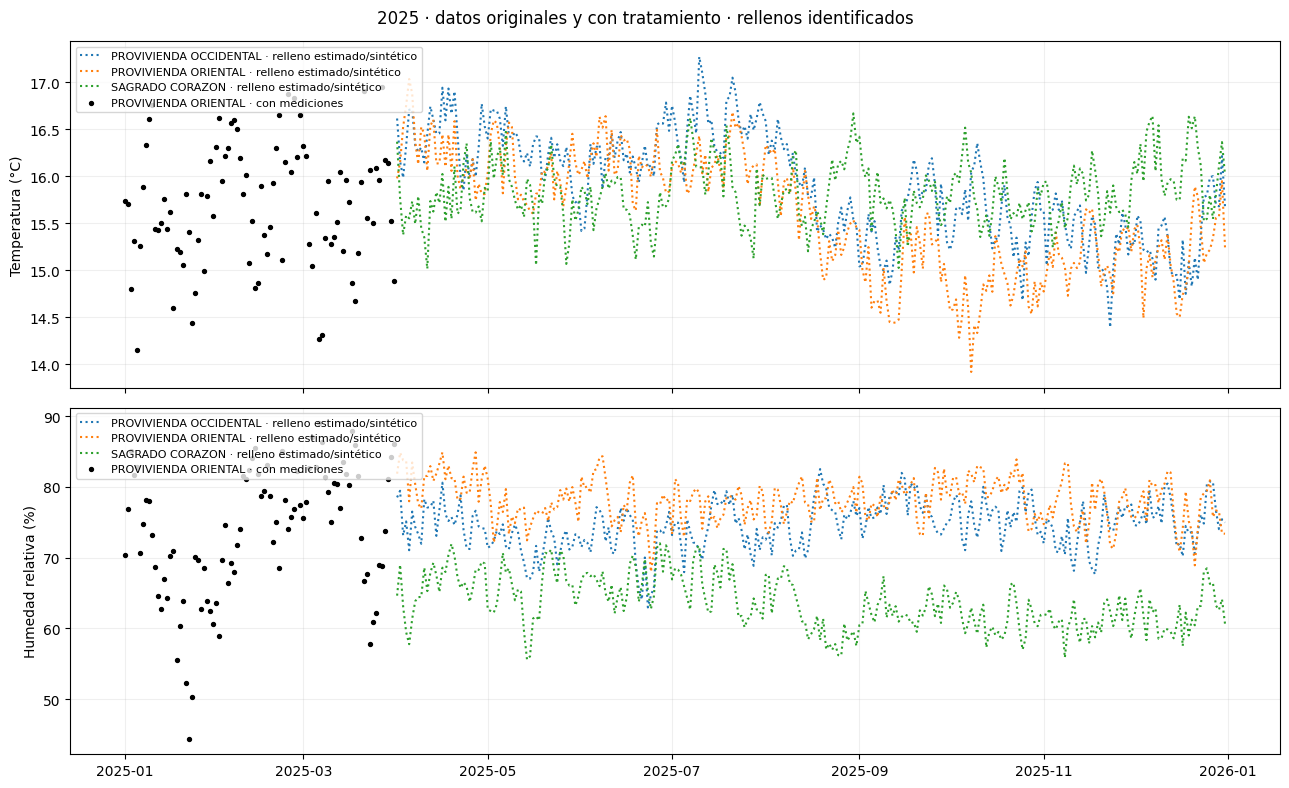

In [4]:
names = centroids.loc[centroids.neighborhood.str.contains('SAGRADO CORAZON|PROVIVIENDA', regex=True), 'neighborhood'].tolist()[:3]
observed = maps.series(2025, 'all', 'observed', names)
supported = observed.copy()
scenario = maps.series(2025, 'all', 'estimated', names, variation=10)
baseline = maps.series(2025, 'all', 'estimated', names, variation=0)
for var in VARIABLES:
    mask = supported[var].notna()
    np.testing.assert_allclose(scenario.loc[mask, var], supported.loc[mask, var])
    assert scenario[f'{var}_simulated_days'].sum() > 0
display(pd.DataFrame({'variable': list(VARIABLES), 'rango_P95_P5': [manifest['simulation']['scale_by_variable'][v] for v in VARIABLES]}))

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, var in zip(axes, ['temperature', 'humidity']):
    for name, group in scenario.groupby('neighborhood'):
        fake = group[f'{var}_origin'].eq('simulated')
        ax.plot(group.datetime, group[var].where(fake), linestyle=':', label=name.split(',')[0]+' · relleno estimado/sintético')
    real = observed.loc[observed.neighborhood.eq(names[0])]
    ax.scatter(real.datetime, real[var], s=8, color='black', label=names[0].split(',')[0]+' · con mediciones', zorder=3)
    ax.set_ylabel(f'{VARIABLES[var][0]} ({VARIABLES[var][1]})')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('2025 · datos originales y con tratamiento · rellenos identificados')
fig.tight_layout()
plt.show()


In [5]:
# El escenario es estable al cambiar mes, orden o selección de sectores.
april = maps.series(2025, 4, 'estimated', list(reversed(names)), variation=10)
pd.testing.assert_frame_equal(april, scenario.loc[scenario.datetime.dt.month.eq(4)].reset_index(drop=True))
for var in VARIABLES:
    np.testing.assert_allclose(scenario[var], maps.series(2025, 'all', 'estimated', names, variation=10)[var])
assert scenario.humidity.between(0, 100).all()
assert scenario[['pm_25', 'pm_10']].ge(0).all().all()

# Diagnóstico de repetición: no mide precisión ni demuestra realismo climático.
rows = []
for name in names:
    for var in ['temperature', 'humidity']:
        for label, frame in [('base sin ruido', baseline), ('tratamiento 10 %', scenario)]:
            values = frame.loc[frame.neighborhood.eq(name) & frame.datetime.ge('2025-04-01'), var]
            rows.append({'sector': name.split(',')[0], 'variable': var, 'escenario': label,
                         'correlación_desfase_7_días': values.autocorr(7)})
display(pd.DataFrame(rows).round(3))


,sector,variable,escenario,correlación_desfase_7_días
0,PROVIVIENDA ORIENTAL,temperature,base sin ruido,0.956
1,PROVIVIENDA ORIENTAL,temperature,tratamiento 10 %,0.751
2,PROVIVIENDA ORIENTAL,humidity,base sin ruido,0.645
3,PROVIVIENDA ORIENTAL,humidity,tratamiento 10 %,0.074
4,SAGRADO CORAZON,temperature,base sin ruido,0.955
5,SAGRADO CORAZON,temperature,tratamiento 10 %,0.003
6,SAGRADO CORAZON,humidity,base sin ruido,0.962
7,SAGRADO CORAZON,humidity,tratamiento 10 %,0.315
8,PROVIVIENDA OCCIDENTAL,temperature,base sin ruido,0.959
9,PROVIVIENDA OCCIDENTAL,temperature,tratamiento 10 %,0.671


## Coherencia de mapa, promedios y descargas

El mapa y las curvas agregan exactamente las mismas series del modo seleccionado.
Los meses se calculan con sus días representados; los huecos no cuentan como cero.
Un promedio con pocos días no es representativo de todo el año. En Datos con tratamiento,
los promedios mezclan días con fuentes y días sintéticos, identificados en el CSV.
Los 1.160 polígonos permanecen incluso si todos sus valores quedan vacíos.

In [6]:
annual, info = maps.aggregates(2025, 'all', 'estimated', 10)
exported = maps.export_aggregates(2025, 'all', 'estimated', 10)
assert len(annual) == len(centroids) == 1160
for mean, var in maps.METRICS.items():
    expected = scenario.groupby('neighborhood')[var].mean()
    np.testing.assert_allclose(annual.set_index('neighborhood').loc[expected.index, mean], expected)
    np.testing.assert_allclose(exported.set_index('neighborhood').loc[expected.index, mean], expected)
    counts = info[var]
    assert counts['source_days'] + counts['short_gap_days'] + counts['simulated_days'] == counts['represented_days']
display(exported.loc[exported.neighborhood.isin(names), ['neighborhood', 'temperature_mean', 'temperature_source_days', 'temperature_simulated_days', 'dataset_mode', 'variation_percent', 'simulation_seed']])


,neighborhood,temperature_mean,temperature_source_days,temperature_simulated_days,dataset_mode,variation_percent,simulation_seed
114,"PROVIVIENDA ORIENTAL, 004503 (115)",15.621466,90,275,estimated,10.0,20251024
190,"SAGRADO CORAZON, 008101 (191)",15.725052,90,275,estimated,10.0,20251024
228,"PROVIVIENDA OCCIDENTAL, 004613 (229)",15.763355,90,275,estimated,10.0,20251024


## Alcance de la comprobación temporal y del modelo HGB

La tabla siguiente evalúa únicamente la **base KNN sin ruido** con fechas de
entrenamiento hasta el 21 de marzo y comprobación del 25 al 31 de marzo de 2025.
No calibra la simulación ni valida periodos ausentes de otros años, el relleno
corto o la precisión espacial. Retirar el día semanal no garantiza mejorar las
métricas: el objetivo de esta corrección es evitar presentar el relleno extenso
como un histórico y separar las hipótesis sintéticas.

Los datos y artefactos de entrenamiento HGB se comprueban por hash. Este notebook
no incorpora al modelo datos interpolados, bases de escenario o variación aleatoria.

In [7]:
import hashlib
display(pd.DataFrame(manifest['temporal_check']))
forecast = json.loads((ROOT/'data/forecasts/hgb_historical.json').read_text(encoding='utf-8'))
assert manifest['used_to_train_forecast_model'] is False
for path, digest in forecast['input_sha256'].items():
    assert '/maps/' not in path
    assert hashlib.sha256((ROOT/path).read_bytes()).hexdigest() == digest
print('Fuentes del HGB intactas. La variación no representa nuevas observaciones ni mayor precisión.')


,variable,unit,n,mae,rmse,baseline_last_available_mae,train_report_end,test_report_start,test_report_end
0,pm_25,µg/m³,119,11.503675,12.314433,15.770187,2025-03-21,2025-03-25,2025-03-31
1,pm_10,µg/m³,126,19.945883,22.752261,23.348089,2025-03-21,2025-03-25,2025-03-31
2,temperature,°C,105,0.510880,0.636885,0.921825,2025-03-21,2025-03-25,2025-03-31
3,humidity,%,77,5.719516,6.775188,8.060877,2025-03-21,2025-03-25,2025-03-31


Fuentes del HGB intactas. La variación no representa nuevas observaciones ni mayor precisión.
